In [4]:
import sys
from pathlib import Path

# locate repo root
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid
from shared.seed import seed_everything

seed_everything(42)

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"

paths = get_experiment_paths("08_pix2pix_facades")
paths

ExperimentPaths(root=WindowsPath('D:/Projects/GANs'), exp_dir=WindowsPath('D:/Projects/GANs/experiments/08_pix2pix_facades'), models_dir=WindowsPath('D:/Projects/GANs/experiments/08_pix2pix_facades/models'), samples_dir=WindowsPath('D:/Projects/GANs/experiments/08_pix2pix_facades/samples'), datasets_dir=WindowsPath('D:/Projects/GANs/datasets'))

In [5]:
import urllib.request
import tarfile
from pathlib import Path

dataset_dir = paths.datasets_dir / "facades"
dataset_dir.mkdir(parents=True, exist_ok=True)

url = "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz"
archive = dataset_dir / "facades.tar.gz"

if not archive.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, archive)

extract_path = dataset_dir / "facades"

if not extract_path.exists():
    print("Extracting dataset...")
    with tarfile.open(archive) as tar:
        tar.extractall(dataset_dir)

extract_path

WindowsPath('D:/Projects/GANs/datasets/facades/facades')

In [6]:
class FacadesDataset(Dataset):

    def __init__(self, root_dir):

        self.files = list(Path(root_dir).glob("*.jpg"))

        self.transform = transforms.Compose([
            transforms.Resize((256,512)),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(self.files[idx]).convert("RGB")
        img = self.transform(img)

        _, h, w = img.shape
        w = w // 2

        photo = img[:, :, :w]     # real building
        seg = img[:, :, w:]       # segmentation

        return seg, photo

In [7]:
train_dir = extract_path / "train"

dataset = FacadesDataset(train_dir)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

len(dataset)

400

In [8]:
def down_block(in_ch,out_ch):

    return nn.Sequential(
        nn.Conv2d(in_ch,out_ch,4,2,1,bias=False),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2,True)
    )

def up_block(in_ch,out_ch):

    return nn.Sequential(
        nn.ConvTranspose2d(in_ch,out_ch,4,2,1,bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(True)
    )


class Generator(nn.Module):

    def __init__(self):

        super().__init__()

        self.d1 = down_block(3,64)
        self.d2 = down_block(64,128)
        self.d3 = down_block(128,256)
        self.d4 = down_block(256,512)
        self.d5 = down_block(512,512)

        self.u1 = up_block(512,512)
        self.u2 = up_block(1024,256)
        self.u3 = up_block(512,128)
        self.u4 = up_block(256,64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128,3,4,2,1),
            nn.Tanh()
        )

    def forward(self,x):

        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)

        u1 = self.u1(d5)
        u2 = self.u2(torch.cat([u1,d4],1))
        u3 = self.u3(torch.cat([u2,d3],1))
        u4 = self.u4(torch.cat([u3,d2],1))

        out = self.final(torch.cat([u4,d1],1))

        return out

In [9]:
class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Conv2d(6,64,4,2,1),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(64,128,4,2,1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(128,256,4,2,1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(256,512,4,1,1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(512,1,4,1,1)
        )

    def forward(self,x,y):

        inp = torch.cat([x,y],1)

        return self.net(inp)

In [43]:
G = Generator().to(device)
D = Discriminator().to(device)

gan_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()

g_opt = optim.Adam(G.parameters(),lr=2e-4,betas=(0.5,0.999))
d_opt = optim.Adam(D.parameters(),lr=2e-4,betas=(0.5,0.999))

In [ ]:
epochs = 100

for epoch in range(1,epochs+1):

    pbar = tqdm(loader)

    for A,B in pbar:

        A = A.to(device)
        B = B.to(device)

        # Train D

        fake_B = G(A).detach()

        real_pred = D(A,B)
        fake_pred = D(A,fake_B)

        real_loss = gan_loss(real_pred,torch.ones_like(real_pred))
        fake_loss = gan_loss(fake_pred,torch.zeros_like(fake_pred))

        d_loss = (real_loss + fake_loss) * 0.5

        d_opt.zero_grad()
        d_loss.backward()
        d_opt.step()

        # Train G

        fake_B = G(A)

        pred = D(A,fake_B)

        adv_loss = gan_loss(pred,torch.ones_like(pred))
        recon_loss = l1_loss(fake_B,B)*100

        g_loss = adv_loss + recon_loss

        g_opt.zero_grad()
        g_loss.backward()
        g_opt.step()

        pbar.set_postfix(
            d_loss=float(d_loss),
            g_loss=float(g_loss)
        )

    G.eval()

    with torch.no_grad():

        A,B = next(iter(loader))

        A = A.to(device)

        fake = G(A)

        grid = torch.cat([A,fake],0)

        save_grid(
            grid,
            paths.samples_dir / f"epoch_{epoch:03d}.png",
            nrow=4
        )

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "g_opt": g_opt.state_dict(),
        "d_opt": d_opt.state_dict(),
    }, paths.models_dir / f"ckpt_epoch_{epoch:03d}.pth")

    G.train()

100%|██████████| 100/100 [00:06<00:00, 16.43it/s, d_loss=0.00141, g_loss=18]  


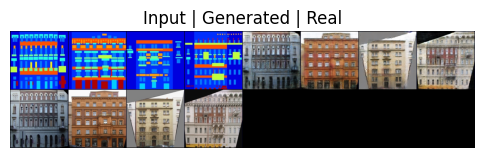

In [45]:
G.eval()

A, B = next(iter(loader))

A = A.to(device)
B = B.to(device)

with torch.no_grad():
    fake = G(A)

show_grid(
    torch.cat([
        A.cpu(),
        fake.cpu(),
        B.cpu()
    ], 0),
    title="Input | Generated | Real"
)

In [1]:
from pathlib import Path
import torch

def latest_ckpt(models_dir: Path):
    ckpts = sorted(models_dir.glob("ckpt_epoch_*.pth"))
    if not ckpts:
        return None
    return ckpts[-1]

In [10]:
G = Generator().to(device)
D = Discriminator().to(device)

gan_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()

g_opt = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_opt = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

In [11]:
ckpt_path = latest_ckpt(paths.models_dir)

start_epoch = 1

if ckpt_path is not None:
    print("Loading checkpoint:", ckpt_path)
    ckpt = torch.load(ckpt_path, map_location=device)

    G.load_state_dict(ckpt["G"])
    D.load_state_dict(ckpt["D"])

    if "g_opt" in ckpt:
        g_opt.load_state_dict(ckpt["g_opt"])
    if "d_opt" in ckpt:
        d_opt.load_state_dict(ckpt["d_opt"])

    start_epoch = ckpt["epoch"] + 1
    print("Resuming from epoch", start_epoch)
else:
    print("No checkpoint found. Starting fresh.")

Loading checkpoint: D:\Projects\GANs\experiments\08_pix2pix_facades\models\ckpt_epoch_100.pth
Resuming from epoch 101


In [12]:
epochs = 200

for epoch in range(start_epoch, epochs + 1):

    pbar = tqdm(loader)

    for A,B in pbar:

        A = A.to(device)
        B = B.to(device)

        # Train D

        fake_B = G(A).detach()

        real_pred = D(A,B)
        fake_pred = D(A,fake_B)

        real_loss = gan_loss(real_pred,torch.ones_like(real_pred))
        fake_loss = gan_loss(fake_pred,torch.zeros_like(fake_pred))

        d_loss = (real_loss + fake_loss) * 0.5

        d_opt.zero_grad()
        d_loss.backward()
        d_opt.step()

        # Train G

        fake_B = G(A)

        pred = D(A,fake_B)

        adv_loss = gan_loss(pred,torch.ones_like(pred))
        recon_loss = l1_loss(fake_B,B)*100

        g_loss = adv_loss + recon_loss

        g_opt.zero_grad()
        g_loss.backward()
        g_opt.step()

        pbar.set_postfix(
            d_loss=float(d_loss),
            g_loss=float(g_loss)
        )

    G.eval()

    with torch.no_grad():

        A,B = next(iter(loader))

        A = A.to(device)

        fake = G(A)

        grid = torch.cat([A,fake],0)

        save_grid(
            grid,
            paths.samples_dir / f"epoch_{epoch:03d}.png",
            nrow=4
        )

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "g_opt": g_opt.state_dict(),
        "d_opt": d_opt.state_dict(),
    }, paths.models_dir / f"ckpt_epoch_{epoch:03d}.pth")

    G.train()

  0%|          | 0/100 [00:00<?, ?it/s]C:\Users\malih\AppData\Local\Temp\ipykernel_73288\1655366156.py:44: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  d_loss=float(d_loss),
100%|██████████| 100/100 [00:05<00:00, 17.74it/s, d_loss=0.00827, g_loss=13.6]
